# SOD SHOCK TUBE PROBLEM WITH LOW FIDELITY DATA 

## Importing libraries

In [149]:
import pandas as pd # Pandas
import numpy as np # Numpy

# Matplotlib for plotting 
import matplotlib.pyplot as plt

import math # Math
import time # Time

# Residual points generating (Latin hyperbolic sampling)
from pyDOE import lhs

# Import torch libraries
import torch 
from torch import Tensor
import torch.autograd as autograd
import torch.optim as optim
import torch.nn as nn

# saving data files
from numpy import asarray
from numpy import savetxt

## Reading the csv file CFD Data

In [150]:
cfd_data=pd.read_csv('E:\\SOD_SHOCK_TUBE\\CASE1\\DATA_SHOCK_TUBE.csv')
#print(cfd_data.columns)
cfd_data=cfd_data.to_numpy()

t_cor_cfd=cfd_data[:,[0]]
x_cor_cfd=cfd_data[:,[1]]
pressure_cfd=cfd_data[:,[3]]
density_cfd=cfd_data[:,[4]]
velocity_cfd=cfd_data[:,[5]]

train_cfd_data=np.hstack((x_cor_cfd,t_cor_cfd,pressure_cfd,density_cfd,velocity_cfd))
#print(train_cfd_data[238::239])

'''
The train_cfd_data is the cfd training data.
'''

'\nThe train_cfd_data is the cfd training data.\n'

## Check GPU 

In [151]:
torch.cuda.empty_cache()
device=torch.cuda.get_device_name()
print('- Original deivce name:',device)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('- Now device name is :- ',device)

- Original deivce name: NVIDIA GeForce RTX 3060 Laptop GPU
- Now device name is :-  cuda


In [152]:
# Random seed values..
torch.set_default_dtype(torch.float)
torch.manual_seed(789)
np.random.seed(789)

## Generating data set for training the model

In [153]:
# Generate data x (position) from 0 to 1 (100 points)
x_data=np.linspace(0,1,100)[:,None]

# Generating data t(time) from 0 to 0.2s (100 points)
t_data=np.linspace(0,0.2,100)[:,None]

In [154]:
# Generating mesh of the xt data...
X,T=np.meshgrid(x_data,t_data)

xt_train=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))
#print(xt_train)

(321, 2)


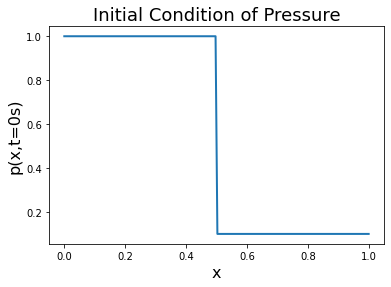

'\n Above is: Just a plot command to check the initial condition pressure is correct\nor not (it is correct). \n'

In [155]:
# Inititial values...
#print(train_cfd_data.shape)
initial_values=train_cfd_data[:239]  # [x,t,p,Rho,u] # Initial Values
#print(initial_values)

boundary_values=np.vstack((train_cfd_data[0::239],train_cfd_data[238::239]))
#print(boundary_values)

x_train=np.vstack((initial_values[:,0:2],boundary_values[:,0:2]))
print(x_train.shape)

u_train=np.vstack((initial_values[:,2:],boundary_values[:,2:]))
#print(u_train)

plt.plot(x_train[0:239,[0]],u_train[0:239,[0]],linewidth=2)
plt.title("Initial Condition of Pressure",fontsize=18)
plt.xlabel("x",fontsize=16)
plt.ylabel("p(x,t=0s)",fontsize=16)
plt.show()
'''
 Above is: Just a plot command to check the initial condition pressure is correct
or not (it is correct). 
'''

-  Putting the cfd data with the initial and boundary
<br/>$\rightarrow$ X_train=[Initial_data,Boundary_data,CFD_data]
<br/>$\rightarrow$ U_train=[Initial_U,Boundary_U,CFD_data_U]

In [156]:
# 179
idx=np.random.choice(train_cfd_data.shape[0],20,replace=False)
x_cfd=train_cfd_data[idx,0:2]
#print(x_cfd)
u_cfd=train_cfd_data[idx,2:]
#print(u_cfd)
X_train=np.vstack((x_train,x_cfd))
U_train=np.vstack((u_train,u_cfd))
print(' The shape of X_train is:',X_train.shape,
      '\n','The shape of U_trian is:',U_train.shape)

#savetxt("X_train",x_cfd)
#savetxt("U_train",u_cfd)

 The shape of X_train is: (341, 2) 
 The shape of U_trian is: (341, 3)


In [157]:
# Now generating the random data data for the solution of PDE...
lb=xt_train[0]  # lower limit
ub=xt_train[-1] # Upper limit

Train_points=lb+(ub-lb)*lhs(2,2000)

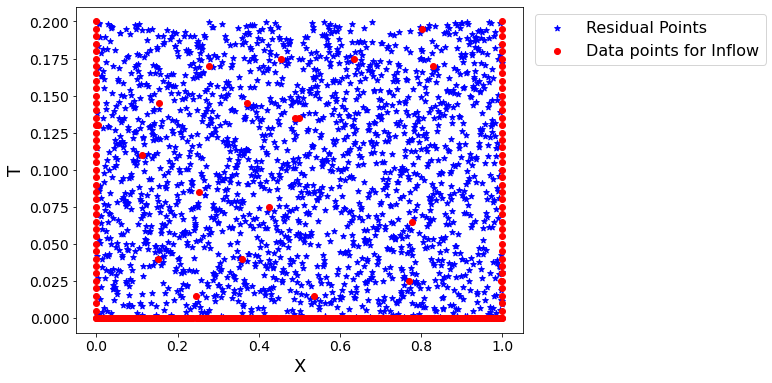

In [158]:
# Ploting the distribution of residual and traing points
plt.figure(figsize=(8,6))

plt.scatter(Train_points[:,[0]],Train_points[:,[1]],marker='*',color='b',
           label='Residual Points')

plt.scatter(X_train[:,[0]],X_train[:,[1]],marker='o',color='r',
            label='Data points for Inflow')
plt.xlabel('X',fontsize=18)
plt.ylabel('T',fontsize=18)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)

plt.legend(loc='center left',bbox_to_anchor=(1.01,0.9),fontsize=16)
plt.show()

In [159]:
X_f_train=np.vstack((Train_points,X_train))
X_train=X_train
U_train=U_train

print(X_f_train.shape)
print(X_train.shape)
print(U_train.shape)

(2341, 2)
(341, 2)
(341, 3)


## Convert float to Tensor

In [160]:
X_f_train=torch.from_numpy(X_f_train).float().to(device)
X_train=torch.from_numpy(X_train).float().to(device)
U_train=torch.from_numpy(U_train).float().to(device)

f_hat=torch.zeros(X_f_train.shape[0],1).to(device)
print(f_hat.shape)

torch.Size([2341, 1])


## PINNS

In [161]:
class ShockTube(nn.Module):
    
    def __init__(self,layers):
        
        # Inherentance: Taking the function from nn.Module
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the loss function as mean square loss
        self.MSELoss=nn.MSELoss(reduction='mean')
        
        # Generating the ModuleList
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # iteration
        self.iter=0
        
        # Defining the Xavier normal for weights and zero as bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3)
            nn.init.zeros_(self.linears[i].bias.data)
    
    # Forward pass funtion
    def forward(self,X):
        # Cgeck whether X data is Tensor or not
        if torch.is_tensor(X)==False:
            X=torch.from_numpy(X).float()
        
        # Converting the boundary values (Min, max)
        LLimit=torch.from_numpy(lb).float().to(device)
        ULimit=torch.from_numpy(ub).float().to(device)
        
        # Feature scale
        X = (X-LLimit)/(ULimit-LLimit)
        
        a=X.float()
        
        # Taking the Pressure density and velocity
        P_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        Rho_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        U_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # forward pass lopp upto the second last layer
        for i in range(len(layers)-2):
            z1=self.linears[i](P_Pred)
            z2=self.linears[i](Rho_Pred)
            z3=self.linears[i](U_Pred)
            
            # activation function
            P_Pred=self.activation(z1)
            Rho_Pred=self.activation(z2)
            U_Pred=self.activation(z3)
            
        # Pass the data to the last layer
        P_Pred=self.linears[-1](P_Pred)
        Rho_Pred=self.linears[-1](Rho_Pred)
        U_Pred=self.linears[-1](U_Pred)
        
        # a=[pressure, denisty, velocity]
        a=torch.cat((P_Pred,Rho_Pred,U_Pred),1)   #print('shape of a:',a.shape)
        
        return a
    
    # Boundary loss function
    def LossBC(self,X,Y):
        
        # Forward pass the X data for boundary and initial values 
        Pred_Val=self.forward(X)
        
        #
        PRED_P=Pred_Val[:,[0]]
        PRED_RHO=Pred_Val[:,[1]]
        PRED_U=Pred_Val[:,[2]]
        
        #print(PRED_P.shape,'\n',Y[:,[0]].shape)
        # Calculating the MSE Loss of predicted data
        Loss_P=self.MSELoss(PRED_P,Y[:,[0]])
        Loss_Rho=self.MSELoss(PRED_RHO,Y[:,[1]])
        Loss_U=self.MSELoss(PRED_U,Y[:,[2]])
        
        # total boundary and initial loss
        Loss_BC=Loss_P+Loss_Rho+Loss_U
        
        # boundary loss
        return Loss_BC
    
    # PDE Loss function
    def LossPDE(self,xy_to_train_f):
        # Gamma for air
        gamma=1.4
        
        g=xy_to_train_f.clone()
        g.requires_grad=True
        
        # Forward pass the data 
        PRHOU=self.forward(g)
        
        # Pressure, Density, and velocity
        P=PRHOU[:,[0]]
        RHO=PRHOU[:,[1]]
        U=PRHOU[:,[2]]
        
        # Calculating the derivative of pressure with respect to x and t
        P_xt=autograd.grad(P,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        P_x=P_xt[:,[0]]
        P_t=P_xt[:,[1]]
        
        # Calculating the derivative of denisty with respect to x and t
        RHO_xt=autograd.grad(RHO,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        RHO_x=RHO_xt[:,[0]]
        RHO_t=RHO_xt[:,[1]]
        
        # Calculating the derivative of velocity with respect to x and t 
        U_xt=autograd.grad(U,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        U_x=U_xt[:,[0]]
        U_t=U_xt[:,[1]]
        
        # Three equations, mass, momentum and energy conservation
        F1=RHO_t + U*(RHO_x) + RHO*U_x
        F2=RHO*(U_t+U*U_x) + P_x
        F3=P_t + gamma*P*U_x + U*P_x
        ##
        
        # MSE Loss function calculating
        LossF1=self.MSELoss(F1,f_hat)
        LossF2=self.MSELoss(F2,f_hat)
        LossF3=self.MSELoss(F3,f_hat)
        
        #Total PDE loss
        LossPDE=LossF1 + LossF2 + LossF3
        
        # Return PDE Loss
        return LossPDE
    
    # Total Loss function
    def Loss(self,X,Y,xy_to_train_f):
        #print('shape of x: ',X.shape)
        
        # Calling the boundary loss function
        Loss1=self.LossBC(X,Y)
        # Calling the pde loss function
        Loss2=self.LossPDE(xy_to_train_f)
        
        # Total mse loss--> Sum of the PDE loss + Boundary loss
        Total_Loss=Loss1*10 + Loss2*0.1
        
        # DUMP VALUES
        #file1=open('CASE1_BC_LOSS_VALUES.txt','a')
        #file1.write(str(Loss1.item())+'\n')
        #file1.close()
        
        #file2=open('CASE1_PDE_LOSS_VALUES.txt','a')
        #file2.write(str(Loss2.item())+'\n')
        #file2.close()
        
        # Return the Total loss function
        return Total_Loss
    
    # Closure fuunction
    def closure(self):
        # Initial taking the gradient as zero
        optimizer.zero_grad()
        
        # Calling the loss function
        loss=self.Loss(X_train,U_train,X_f_train)
        
        # Backprop
        loss.backward()
        
        # Iteration +=1
        self.iter+=1
        
        # TOTAL LOSS DUMP
        #file3=open('CASE1_SHOCK_TUBE_LOSS.txt','a')
        #file3.write(str(loss.item())+'\n')
        #file3.close()
        
        # Self iteration (Print the loss values at every 100 iteration)
        if self.iter%100==0:
            print(loss)
        
        return loss
    
    # Test function
    def Test(self,Test_data):
        # Forward pass the test data
        res_pred=self.forward(Test_data)
        
        # Detach the values cpu
        res_pred=res_pred.detach().cpu().numpy()
        
        # Pressure , density, velocity
        Pressure_pred=res_pred[:,[0]]
        Density_pred=res_pred[:,[1]]
        Velocity_pred=res_pred[:,[2]]
        
        # Return a=[Pressure, Density, Velocity]
        return [Pressure_pred,Density_pred,Velocity_pred]

In [162]:
layers=[2,80,80,80,80,3] # No of neruons in each layer

# Object of the class
s=ShockTube(layers)

# Passing the object to the device
s.to(device)

# Passing the object to the device
params=list(s.parameters())

# Optimization methods
optimizer=optim.LBFGS(s.parameters(),lr=0.1,max_iter=10000,
                     tolerance_grad=1e-10,max_eval=None,tolerance_change=1e-8,
                     history_size=1000,line_search_fn='strong_wolfe')

# Training time for the optimization
start_time1=time.time()
optimizer.step(s.closure)
Training_time1=time.time()-start_time1

# Training time
print('Trining Time:- ',Training_time1)


tensor(0.4115, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1800, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1118, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0807, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0597, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0469, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0378, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0308, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0261, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0223, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0186, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0155, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0128, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0101, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0085, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0071, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0060, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0052, device='cuda:0', grad_fn=<AddBack

---
---

## TEST_DATA_PREDICTION

## CASE 1 $\rightarrow$ t=0.1 

In [163]:
Case1=[0.1]*100
Case1=np.array(Case1)[:,None]
#print(Case1)

In [164]:
test_data1=np.hstack((xt_train[5000:5100,[0]],Case1))
Test_data1=torch.from_numpy(test_data1).float().to(device)
#print(Test_data1.shape)

- ## EXACT SOLUTION

In [165]:
Exact_val=train_cfd_data[4780:5019]

#print(Exact_val)

presrhovel=Exact_val[:,2:]
x_val=Exact_val[:,0]
Pressure=presrhovel[:,0]
Density=presrhovel[:,1]
Velocity=presrhovel[:,2]
# Exact_val

- ## PREDICTION AND PLOT

In [166]:
[Pressure_pred,Density_Pred,Velocity_Pred]=s.Test(Test_data1)

print(Pressure_pred.shape)
Test_data1=Test_data1.detach().cpu().numpy()

(100, 1)


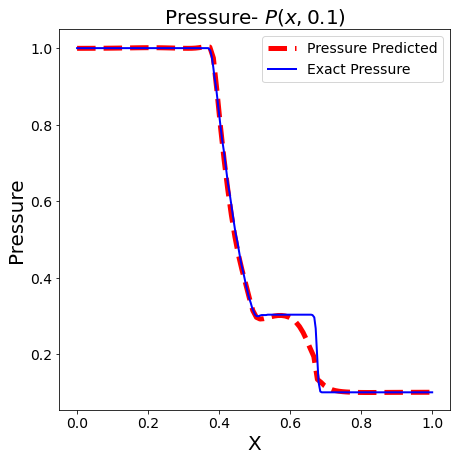

In [167]:
plt.figure(figsize=(7,7))
plt.plot(Test_data1[:,[0]],Pressure_pred,'--',linewidth=5,color='r',
         label='Pressure Predicted')
plt.plot(x_val,Pressure,linewidth=2,color='b',label='Exact Pressure')
plt.plot()
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Pressure",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Pressure- $P(x,0.1)$',fontsize=20)
plt.plot()


x_val=asarray(x_val)
Pressure=asarray(Pressure)
Pressure_pred=asarray(Pressure_pred)
#savetxt('CASE1_X_VAL_01.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_PRESSURE_01.csv',Pressure,delimiter=',')
#savetxt('CASE1_PREDICTED_PRESSURE_01.csv',Pressure_pred,delimiter=',')

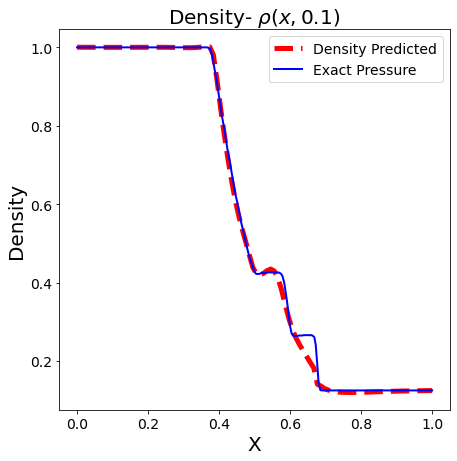

In [168]:
plt.figure(figsize=(7,7))
plt.plot(Test_data1[:,[0]],Density_Pred,'--',linewidth=5,color='r',
         label='Density Predicted')
plt.plot(x_val,Density,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Density",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Density- $\rho (x,0.1)$ ', fontsize=20)
plt.plot()

#x_val=asarray(x_val)
Density=asarray(Density)
Density_pred=asarray(Density_Pred)
#savetxt('CASE1_X_VAL_01.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Density_01.csv',Density,delimiter=',')
#savetxt('CASE1_PREDICTED_Density_01.csv',Density_Pred,delimiter=',')

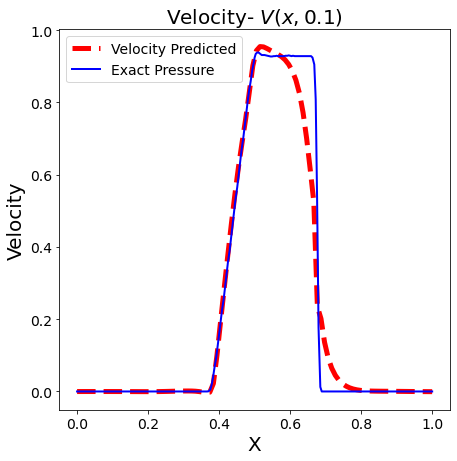

In [169]:
plt.figure(figsize=(7,7))
plt.plot(Test_data1[:,[0]],Velocity_Pred,'--',linewidth=5,color='r',
         label='Velocity Predicted')
plt.plot(x_val,Velocity,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Velocity",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Velocity- $V(x,0.1)$', fontsize=20)
plt.plot()


#x_val=asarray(x_val)
Velocity=asarray(Velocity)
Velocity_Pred=asarray(Velocity_Pred)
#savetxt('CASE1_X_VAL_01.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Velocity_01.csv',Velocity,delimiter=',')
#savetxt('CASE1_PREDICTED_Velocity_01.csv',Velocity_Pred,delimiter=',')

## CASE 2 $\rightarrow$ t=0.15

In [170]:
case2=[0.15]*100
case2=np.array(case2)[:,None]
#print(case2)

In [171]:
test_data2=np.hstack((xt_train[7400:7500,[0]],case2))
Test_data2=torch.from_numpy(test_data2).float().to(device)
print(Test_data2.shape)

torch.Size([100, 2])


## EXACT SOLUTION

In [172]:
Exact_val=train_cfd_data[7170:7409]

#print(Exact_val)

presrhovel=Exact_val[:,2:]
x_val=Exact_val[:,0]
Pressure=presrhovel[:,0]
Density=presrhovel[:,1]
Velocity=presrhovel[:,2]
#Exact_val

- ## PREDICTION AND PLOT

In [173]:
[Pressure_pred,Density_Pred,Velocity_Pred]=s.Test(Test_data2)

print(Pressure_pred.shape)
Test_data2=Test_data2.detach().cpu().numpy()

(100, 1)


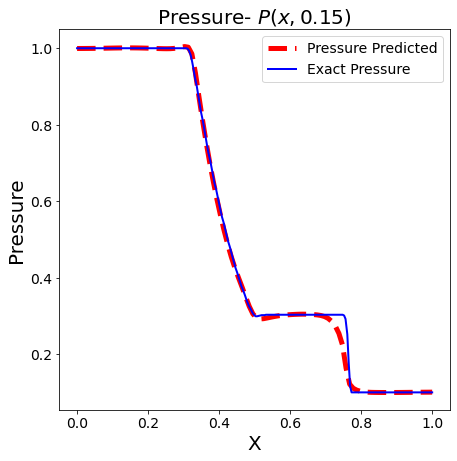

In [174]:
plt.figure(figsize=(7,7))
plt.plot(Test_data2[:,[0]],Pressure_pred,'--',linewidth=5,color='r',
         label='Pressure Predicted')
plt.plot(x_val,Pressure,linewidth=2,color='b',label='Exact Pressure')
plt.plot()
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Pressure",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Pressure- $P(x,0.15)$',fontsize=20)
plt.plot()

x_val=asarray(x_val)
Pressure=asarray(Pressure)
Pressure_pred=asarray(Pressure_pred)
#savetxt('CASE1_X_VAL_015.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_PRESSURE_015.csv',Pressure,delimiter=',')
#savetxt('CASE1_PREDICTED_PRESSURE_015.csv',Pressure_pred,delimiter=',')

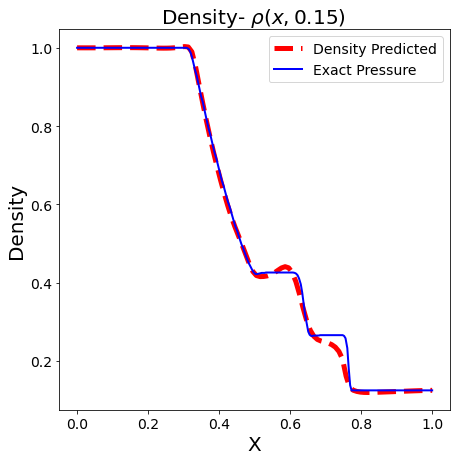

In [175]:
plt.figure(figsize=(7,7))
plt.plot(Test_data2[:,[0]],Density_Pred,'--',linewidth=5,color='r',
         label='Density Predicted')
plt.plot(x_val,Density,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Density",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Density- $\rho (x,0.15)$ ', fontsize=20)
plt.plot()


#x_val=asarray(x_val)
Density=asarray(Density)
Density_Pred=asarray(Density_Pred)
#savetxt('CASE1_X_VAL_015.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Density_015.csv',Density,delimiter=',')
#savetxt('CASE1_PREDICTED_Density_015.csv',Density_Pred,delimiter=',')

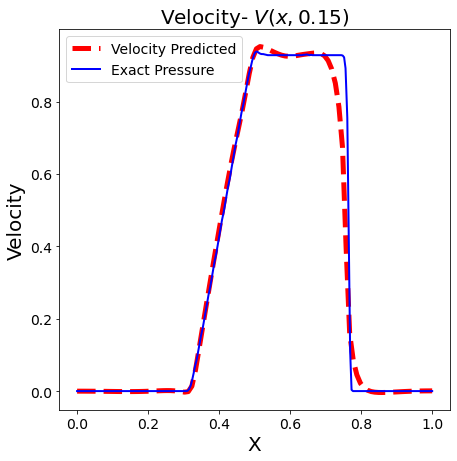

In [176]:
plt.figure(figsize=(7,7))
plt.plot(Test_data2[:,[0]],Velocity_Pred,'--',linewidth=5,color='r',
         label='Velocity Predicted')
plt.plot(x_val,Velocity,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Velocity",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Velocity- $V(x,0.15)$', fontsize=20)
plt.plot()

#x_val=asarray(x_val)
Velocity=asarray(Velocity)
Velocity_Pred=asarray(Velocity_Pred)
#savetxt('CASE1_X_VAL_01.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Velocity_015.csv',Velocity,delimiter=',')
#savetxt('CASE1_PREDICTED_Velocity_015.csv',Velocity_Pred,delimiter=',')

## CASE 3 $\rightarrow$ t=0.2


In [177]:
Case3=[0.2]*100
Case3=np.array(Case3)[:,None]
#print(Case3)

In [178]:
test_data3=np.hstack((xt_train[9900:10000,[0]],Case3))
Test_data3=torch.from_numpy(test_data3).float().to(device)
print(Test_data3.shape)

torch.Size([100, 2])


## EXACT SOLUTION

In [179]:
Exact_solution=train_cfd_data[9560:]

#print(Exact_solution)

presrhovel=Exact_solution[:,2:]
x_val=Exact_solution[:,0]
Pressure=presrhovel[:,0]
Density=presrhovel[:,1]
Velocity=presrhovel[:,2]

- ## PREDCITION AND PLOT

In [180]:
[Pressure_pred,Density_Pred,Velocity_Pred]=s.Test(Test_data3)

print(Pressure_pred.shape)
Test_data3=Test_data3.detach().cpu().numpy()

(100, 1)


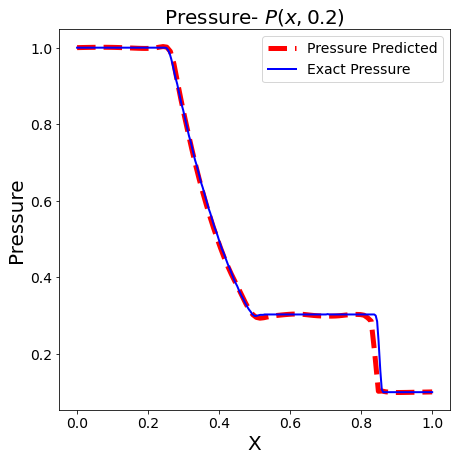

In [181]:
plt.figure(figsize=(7,7))
plt.plot(Test_data3[:,[0]],Pressure_pred,'--',linewidth=5,color='r',
         label='Pressure Predicted')
plt.plot(x_val,Pressure,linewidth=2,color='b',label='Exact Pressure')
plt.plot()
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Pressure",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Pressure- $P(x,0.2)$',fontsize=20)
plt.plot()

x_val=asarray(x_val)
Pressure=asarray(Pressure)
Pressure_pred=asarray(Pressure_pred)
#savetxt('CASE1_X_VAL_02.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_PRESSURE_02.csv',Pressure,delimiter=',')
#savetxt('CASE1_PREDICTED_PRESSURE_02.csv',Pressure_pred,delimiter=',')

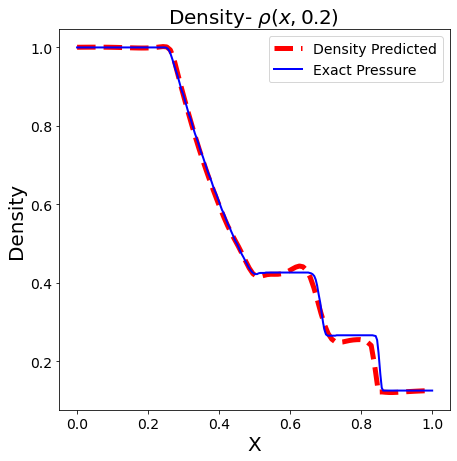

In [182]:
plt.figure(figsize=(7,7))
plt.plot(Test_data3[:,[0]],Density_Pred,'--',linewidth=5,color='r',
         label='Density Predicted')
plt.plot(x_val,Density,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Density",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Density- $\rho (x,0.2)$ ', fontsize=20)
plt.plot()

#x_val=asarray(x_val)
Density=asarray(Density)
Density_Pred=asarray(Density_Pred)
#savetxt('CASE1_X_VAL_015.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Density_02.csv',Density,delimiter=',')
#savetxt('CASE1_PREDICTED_Density_02.csv',Density_Pred,delimiter=',')

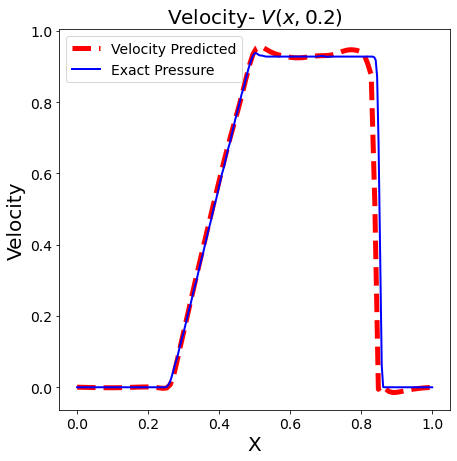

In [183]:
plt.figure(figsize=(7,7))
plt.plot(Test_data3[:,[0]],Velocity_Pred,'--',linewidth=5,color='r',
         label='Velocity Predicted')
plt.plot(x_val,Velocity,linewidth=2,color='b',label='Exact Pressure')
plt.legend(fontsize=14)
plt.xlabel('X',fontsize=20)
plt.ylabel("Velocity",fontsize=20)
plt.tick_params(axis='x',labelsize=14)
plt.tick_params(axis='y',labelsize=14)
plt.title(r'Velocity- $V(x,0.2)$', fontsize=20)
plt.plot()

#x_val=asarray(x_val)
Velocity=asarray(Velocity)
Velocity_Pred=asarray(Velocity_Pred)
#savetxt('CASE1_X_VAL_01.csv',x_val,delimiter=',')
#savetxt('CASE1_ACTUAL_Velocity_02.csv',Velocity,delimiter=',')
#savetxt('CASE1_PREDICTED_Velocity_02.csv',Velocity_Pred,delimiter=',')

In [184]:
Error_Pressure=0
Error_Pressure_sum=0
Error_Density=0
Error_Density_sum=0
Error_Velocity=0
Error_Velocity_sum=0

# for error
#print(Exact_solution.shape)
X_VALUES_TEST=Exact_solution[:,0:2]


X_VALUES_TEST=torch.from_numpy(X_VALUES_TEST).float().to(device)
print(X_VALUES_TEST.shape)


[Pressure_pred,Density_Pred,Velocity_Pred]=s.Test(X_VALUES_TEST)

print(Pressure_pred.shape)
X_VALUES_TEST=X_VALUES_TEST.detach().cpu().numpy()


torch.Size([239, 2])
(239, 1)


In [185]:
for i in range(len(X_VALUES_TEST)):
    Error_Pressure+=((Pressure_pred[i,0]-Pressure[i])**2)
    Error_Pressure_sum+=(Pressure[i])**2
    
    Error_Density+=((Density_Pred[i,0]-Density[i])**2)
    Error_Density_sum+=(Pressure[i])**2
    
    Error_Velocity+=((Velocity_Pred[i,0]-Velocity[i])**2)
    Error_Velocity_sum+=(Pressure[i])**2

error_Pressure=Error_Pressure**0.5/Error_Pressure_sum**0.5
error_Density=Error_Density**0.5/Error_Density_sum**0.5
error_Velocity=Error_Velocity**0.5/Error_Velocity_sum**0.5


print("Density Error=",error_Density)
print("Velocity Error=",error_Velocity)
print("Pressure Error=",error_Pressure)

Density Error= 0.026389161136517604
Velocity Error= 0.14204880815984203
Pressure Error= 0.030668427335994827


---
---